In [28]:
import torch
import torch.nn as nn
from matplotlib import pyplot as plt
import numpy as np

import pennylane as qp 


from qiskit import transpile
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import ZFeatureMap, EfficientSU2
from qiskit.quantum_info import SparsePauliOp
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.connectors import TorchConnector
from qiskit_algorithms.gradients import ReverseEstimatorGradient
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 
from qiskit_ibm_runtime.options import EstimatorOptions



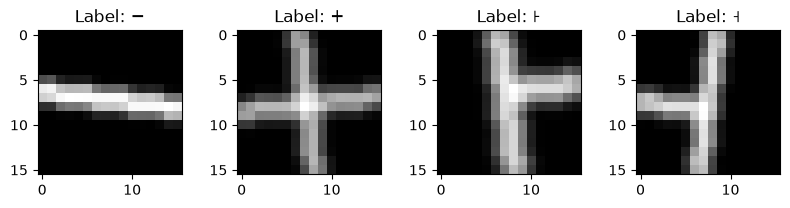

In [3]:
[pm] = qp.data.load('other', name='plus-minus')

X_train = pm.img_train  # shape (1000,16,16)
X_test = pm.img_test  # shape (200,16,16)
Y_train = pm.labels_train  # shape (1000,)
Y_test = pm.labels_test  # shape (200,)

x_vis = [
    (X_train[Y_train == 0])[0],
    (X_train[Y_train == 1])[0],
    (X_train[Y_train == 2])[0],
    (X_train[Y_train == 3])[0],
]
y_vis = [0, 1, 2, 3]

def visualize_data(x, y, pred=None):
    n_img = len(x)
    labels_list = ["\u2212", "\u002b", "\ua714", "\u02e7"]
    fig, axes = plt.subplots(1, 4, figsize=(8, 2))
    for i in range(n_img):
        axes[i].imshow(x[i], cmap="gray")
        if pred is None:
            axes[i].set_title("Label: {}".format(labels_list[y[i]]))
        else:
            axes[i].set_title("Label: {}, Pred: {}".format(labels_list[y[i]], labels_list[pred[i]]))
    plt.tight_layout(w_pad=2)
    plt.show()

visualize_data(x_vis, y_vis)

In [35]:


class QiskitReuploadingClassifier(nn.Module):
    def __init__(self, input_dim=256, output_dim=4, num_qubits=8, num_layers=32, num_reup=3, estimator=None, backend=None):
        super().__init__()
        torch.manual_seed(1337)
        self.num_qubits = num_qubits
        self.output_dim = output_dim
        self.num_layers = num_layers
        self.num_reup = num_reup
        
        #3 rotations per qubit per layer
        self.total_angles = num_layers * num_qubits * 3 # 32 * 8 * 3 = 768
    
    
        self.weights = nn.Parameter(0.1 * torch.rand(self.total_angles))
        self.bias = nn.Parameter(0.1 * torch.rand(self.total_angles))
        
        self.qc, self.params = self._build_strongly_entangling_circuit()
        if backend is not None:
            self.qc = transpile(
                self.qc,
                backend=backend,
                optimization_level=1,
            )

        self.params = list(self.qc.parameters)
        
        self.observables = [SparsePauliOp.from_sparse_list([("Z", [i], 1)],num_qubits=self.num_qubits,) for i in range(self.output_dim)]

        if backend is not None and self.qc.layout is not None:
            self.observables = [
                obs.apply_layout(self.qc.layout)
                for obs in self.observables
            ]
        
        qnn = EstimatorQNN(
            circuit=self.qc,
            observables=self.observables,
            input_params=self.params,
            weight_params=[],
            estimator=estimator,
            input_gradients=True,
            gradient=ReverseEstimatorGradient(),  
        )
        
        self.qcircuit = TorchConnector(qnn)

    def _build_strongly_entangling_circuit(self):
     qc = QuantumCircuit(self.num_qubits)
     params = ParameterVector('θ', self.total_angles)
        
     idx = 0
     for layer in range(self.num_layers):
        for q in range(self.num_qubits):
             qc.rz(params[idx], q)
             qc.ry(params[idx+1], q)
             qc.rz(params[idx+2], q)
             idx += 3
                
        step = (layer % (self.num_qubits - 1)) + 1
        for q in range(self.num_qubits):
            target = (q + step) % self.num_qubits
            qc.cx(q, target)
                
     return qc, params

    def forward(self, x):
        x_stacked = torch.cat([x] * self.num_reup, dim=1) 
        angles = self.weights * x_stacked + self.bias
        return self.qcircuit(angles)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = QiskitReuploadingClassifier().to(device)

dummy_data = torch.rand(5, 256).to(device) 
output = model(dummy_data)

print("Output shape:", output.shape) # Expected: [5, 4]

Using device: cpu
Output shape: torch.Size([5, 4])


In [36]:

input_dim = 256
num_classes = 4
num_layers = 32
num_qubits = 8
num_reup = 3

qml_model = QiskitReuploadingClassifier(
    input_dim=256, 
    output_dim=4,     
    num_qubits=8, 
    num_layers=32
).to(device)


In [37]:
#### Hyperparameters ####
learning_rate = 0.1
epochs = 4
batch_size = 20

feats_train = torch.from_numpy(X_train[:200]).reshape(200, -1).float().to(device)
feats_test = torch.from_numpy(X_test[:50]).reshape(50, -1).float().to(device)
labels_train = torch.from_numpy(Y_train[:200]).long().to(device)
labels_test = torch.from_numpy(Y_test[:50]).long().to(device)
num_train = feats_train.shape[0]

qml_model = QiskitReuploadingClassifier(
    input_dim=input_dim, 
    output_dim=num_classes, 
    num_qubits=num_qubits, 
    num_layers=num_layers
).to(device)

loss = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(qml_model.parameters(), lr=learning_rate)
num_batches = num_train // batch_size

def accuracy(labels, predictions):
    predicted_classes = torch.argmax(predictions, dim=1)
    correct = (predicted_classes == labels).sum().item()
    return correct / len(labels)

def gen_batches(num_samples, num_batches):
    assert num_samples % num_batches == 0
    perm_ind = torch.reshape(torch.randperm(num_samples), (num_batches, -1))
    return perm_ind


def print_acc(epoch, max_ep=4):
    with torch.no_grad():
        predictions_train = qml_model(feats_train[:50])
        predictions_test = qml_model(feats_test)
        
        cost_approx_train = loss(predictions_train, labels_train[:50])
        cost_approx_test = loss(predictions_test, labels_test)
        
        acc_approx_train = accuracy(labels_train[:50], predictions_train)
        acc_approx_test = accuracy(labels_test, predictions_test)
        
    print(
        f"Epoch {epoch}/{max_ep} | Approx Cost (train): {cost_approx_train:0.7f} | Cost (val): {cost_approx_test:0.7f} |"
        f" Approx Acc train: {acc_approx_train:0.7f} | Acc val: {acc_approx_test:0.7f}"
    )


Starting training loop for Qiskit variational classifier (8 qubits, 32 layers)...
Epoch 0/4 | Approx Cost (train): 1.3883215 | Cost (val): 1.3875421 | Approx Acc train: 0.1600000 | Acc val: 0.1200000
Epoch 1/4 | Approx Cost (train): 1.2474105 | Cost (val): 1.2367988 | Approx Acc train: 0.8200000 | Acc val: 0.8800000
Epoch 2/4 | Approx Cost (train): 1.1586365 | Cost (val): 1.1770498 | Approx Acc train: 0.9800000 | Acc val: 0.9600000
Epoch 3/4 | Approx Cost (train): 1.0625497 | Cost (val): 1.0833808 | Approx Acc train: 0.9600000 | Acc val: 0.9800000
Epoch 4/4 | Approx Cost (train): 0.9996886 | Cost (val): 1.0047663 | Approx Acc train: 1.0000000 | Acc val: 0.9800000
Model weights saved to qiskit_reuploading_classifier.pth


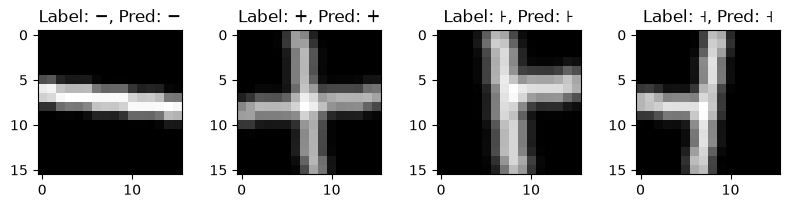

In [ ]:
print(f"Starting training loop for Qiskit variational classifier ({num_qubits} qubits, {num_layers} layers)...")

for ep in range(epochs):
    batch_ind = gen_batches(num_train, num_batches)
    print_acc(epoch=ep, max_ep=epochs)

    for it in range(num_batches):
        optimizer.zero_grad()
        
        feats_train_batch = feats_train[batch_ind[it]]
        labels_train_batch = labels_train[batch_ind[it]]
        outputs = qml_model(feats_train_batch)
        batch_loss = loss(outputs, labels_train_batch)
        batch_loss.backward()
        optimizer.step()

print_acc(epochs, max_ep=epochs)


save_path = "qiskit_reuploading_classifier.pth"
torch.save({
    "model_state_dict": qml_model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epoch": epochs,
    "learning_rate": learning_rate,
}, save_path)
print(f"Model weights saved to {save_path}")

x_vis_torch = torch.from_numpy(np.array(x_vis).reshape(4, -1)).float().to(device)
y_vis_torch = torch.from_numpy(np.array(y_vis)).long().to(device)

with torch.no_grad():
    benign_preds = qml_model(x_vis_torch)

benign_class_output = torch.argmax(benign_preds, dim=1).cpu().numpy()
visualize_data(x_vis, y_vis, benign_class_output)

In [38]:
checkpoint = torch.load("qiskit_reuploading_classifier.pth", map_location=device)

qml_model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
start_epoch = checkpoint["epoch"]

qml_model.eval() 

with torch.no_grad():
    adversarial_preds_before = qml_model(feats_test)

adversarial_class_output_before = torch.argmax(adversarial_preds_before, dim=1)
acc = accuracy(labels_test, adversarial_preds_before)
print(f"Accuracy before PGD Attack: {acc:0.4f}")

Accuracy before PGD Attack: 0.9800


In [10]:
feats_train = torch.from_numpy(X_train[:200]).reshape(200, -1).float().to(device)
feats_test = torch.from_numpy(X_test[:50]).reshape(50, -1).float().to(device)
labels_train = torch.from_numpy(Y_train[:200]).long().to(device)
labels_test = torch.from_numpy(Y_test[:50]).long().to(device)

x_vis_torch = torch.from_numpy(np.array(x_vis).reshape(4, -1)).float().to(device)
y_vis_torch = torch.from_numpy(np.array(y_vis)).long().to(device)

In [40]:
checkpoint = torch.load(
    "qiskit_reuploading_classifier.pth",
    map_location=device,
)

qml_model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
start_epoch = checkpoint["epoch"]


service = QiskitRuntimeService()

backend = service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=8,
)

print(f"Backend: {backend.name}")

options = EstimatorOptions()
options.resilience.zne_mitigation = True
options.resilience.zne.noise_factors = [1, 3, 5]

hardware_estimator = EstimatorV2(
    mode=backend,
    options=options,
)

transpiled_qc = transpile(
    qml_model.qc,
    backend=backend,
    optimization_level=1,
)

checkpoint = torch.load(
    "qiskit_reuploading_classifier.pth",
    map_location=device,
)

hardware_model = QiskitReuploadingClassifier(
    input_dim=input_dim,
    output_dim=num_classes,
    num_qubits=num_qubits,
    num_layers=num_layers,
    estimator=hardware_estimator,
    backend=backend,
).to(device)

hardware_model.load_state_dict(checkpoint["model_state_dict"])
hardware_model.eval()

with torch.no_grad():
    mitigated_predictions = hardware_model(feats_test)


mitigated_acc = accuracy(labels_test, mitigated_predictions)

print(f"Mitigated accuracy on {backend.name}: {mitigated_acc:.4f}")

Backend: ibm_berlin


RuntimeInvalidStateError: 'Unable to retrieve result for job d9ceh7tb31ls73arg630. Job was cancelled.'


After PGD Atack Vis_data:


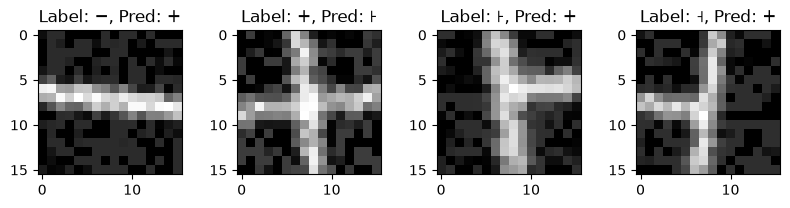

In [12]:

loss_fn = nn.CrossEntropyLoss()

def PGD(model, feats, labels, epsilon=0.1, alpha=0.01, num_iter=10):
    delta = torch.zeros_like(feats, requires_grad=True)
    
    for t in range(num_iter):
        feats_adv = feats + delta
        outputs = model(feats_adv)

        l = loss_fn(outputs, labels)
        l.backward()

        delta.data = (delta + alpha * delta.grad.detach().sign()).clamp(-epsilon, epsilon)
        delta.grad.zero_()
        
    return delta.detach()

perturbations = PGD(model=qml_model, feats=x_vis_torch, labels=y_vis_torch, epsilon=0.1)
perturbed_x = x_vis_torch + perturbations
qml_model.eval()
adversarial_preds_after = qml_model(perturbed_x)
adversarial_class_output_after = torch.argmax(adversarial_preds_after, dim=1)

print("\nAfter PGD Atack Vis_data:")
visualize_data(perturbed_x.cpu().detach().numpy().reshape(-1, 16, 16), y_vis, adversarial_class_output_after.cpu().numpy())


In [13]:
perturbations_test = PGD(model=qml_model, feats=feats_test, labels=labels_test, epsilon=0.1)
perturbed_feats_test = feats_test + perturbations_test


In [14]:
qml_model.eval()

with torch.no_grad():
    adversarial_preds_after = qml_model(perturbed_feats_test)

adversarial_class_output_after = torch.argmax(adversarial_preds_after, dim=1)
adv_acc = accuracy(labels_test, adversarial_preds_after)
print(f"Accuracy AFTER PGD Attack: {adv_acc:0.4f}")

Accuracy AFTER PGD Attack: 0.0400


In [ ]:
adv_dataset = (
    PGD(model=qml_model, feats=feats_train[:20], labels=labels_train[:20], epsilon=0.1)
    + feats_train[:20]
)

feats_retrain = torch.cat((feats_train, adv_dataset))
labels_retrain = torch.cat((labels_train, labels_train[:20]))
epochs_retraining = 2

for ep in range(0, epochs_retraining):
    batch_ind = gen_batches(num_train, num_batches)
    print_acc(epoch=ep, max_ep=2)

    for it in range(num_batches):
        optimizer.zero_grad()
        feats_train_batch = feats_retrain[batch_ind[it]]
        labels_train_batch = labels_retrain[batch_ind[it]]

        outputs = qml_model(feats_train_batch)
        batch_loss = loss(outputs, labels_train_batch)
        # if REG:
        #    loss = loss + lipschitz_regularizer(regularization_rate, model.qcircuit.weights)
        batch_loss.backward()
        optimizer.step()

print_acc(epochs_retraining, max_ep=2)

save_path = "qiskit_reuploading_classifier_after_attack.pth"
torch.save({
    "model_state_dict": qml_model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epoch": epochs,
    "learning_rate": learning_rate,
}, save_path)
print(f"Model weights saved to {save_path}")

Epoch 0/2 | Approx Cost (train): 0.9996886 | Cost (val): 1.0047663 | Approx Acc train: 1.0000000 | Acc val: 0.9800000
Epoch 1/2 | Approx Cost (train): 0.9360812 | Cost (val): 0.9474493 | Approx Acc train: 0.9600000 | Acc val: 0.9600000
Epoch 2/2 | Approx Cost (train): 0.9082251 | Cost (val): 0.9231906 | Approx Acc train: 0.9800000 | Acc val: 0.9600000
Model weights saved to qiskit_reuploading_classifier_after_attack.pth



Dupa atac:


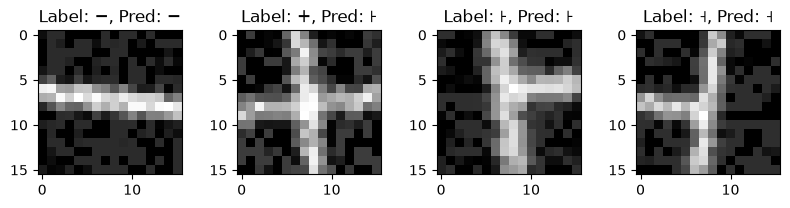

In [10]:
qml_model.eval()
adversarial_preds_after = qml_model(perturbed_x)
adversarial_class_output_after = torch.argmax(adversarial_preds_after, dim=1)

print("\nDupa atac:")
visualize_data(perturbed_x.cpu().detach().numpy().reshape(-1, 16, 16), y_vis, adversarial_class_output_after.cpu().numpy())